<a href="https://colab.research.google.com/github/rohinerd/flood_warnings_classifier/blob/main/flood_warnings_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install libraries

In [10]:
!pip install odfpy -q


### List contents

In [11]:
!ls -la

total 3560
drwxr-xr-x 1 root root    4096 Nov  1 23:08 .
drwxr-xr-x 1 root root    4096 Nov  1 23:05 ..
drwxr-xr-x 4 root root    4096 Oct 26 22:18 .config
-rw-r--r-- 1 root root 3628573 Nov  1 23:08 Historic_Flood_Warnings.zip
drwxr-xr-x 1 root root    4096 Oct 26 22:18 sample_data


## 2. Unzip the flood warnings data

In [12]:
!unzip -o Historic_Flood_Warnings.zip -d flood_data
!ls -lh flood_data

Archive:  Historic_Flood_Warnings.zip
  inflating: flood_data/202607 Historic Flood Warnings Documentation.odt  
  inflating: flood_data/202607 Historic Flood Warnings – EA Only.ods  
total 3.6M
-rw-rw-rw- 1 root root 270K Jul  2 07:39 '202607 Historic Flood Warnings Documentation.odt'
-rw-rw-rw- 1 root root 3.4M Jul  2 08:13 '202607 Historic Flood Warnings – EA Only.ods'


## 3. List the sheets in the EA-only spreadsheet

In [14]:
import glob
import pandas as pd

ods_path = glob.glob("flood_data/*EA Only.ods")[0]
sheets = pd.read_excel(ods_path, engine="odf", sheet_name=None)

for name, sheet in sheets.items():
    print(name, sheet.shape)

tblAllData (85993, 5)


## 4. Inspect the column headers and first rows

In [15]:
df = sheets["tblAllData"]

print(df.columns.tolist())
print(df.head())
print(df.dtypes)

['DATE', 'AREA', 'CODE', 'WARNING / ALERT AREA NAME', 'TYPE']
                 DATE               AREA        CODE  \
0 2006-01-31 13:55:34         SW - Devon   113WACT2a   
1 2006-01-31 16:33:10  SW - North Wessex  112WACTAVN   
2 2006-02-08 11:19:45      ANG - Eastern   054WATBT1   
3 2006-02-08 11:25:26      ANG - Eastern   054WATBT2   
4 2006-02-08 11:32:20      ANG - Eastern   054WATBT3   

           WARNING / ALERT AREA NAME         TYPE  
0                Devon Coast (North)  Flood Watch  
1               Porlock to Avonmouth  Flood Watch  
2  Tidal Rivers Bure, Ant and Thurne  Flood Watch  
3                   Tidal River Yare  Flood Watch  
4                Tidal River Waveney  Flood Watch  
DATE                         datetime64[ns]
AREA                                 object
CODE                                 object
WARNING / ALERT AREA NAME            object
TYPE                                 object
dtype: object


## 5. Check the values in the TYPE column

In [16]:
print(df["TYPE"].value_counts())
print(df["DATE"].min(), df["DATE"].max())

TYPE
Flood Alert                    43325
Flood Warning                  19597
Flood Watch                    11032
Update Flood Alert              5535
Flood alert                     3011
Update Flood Warning            2071
Flood warning                    923
Severe Flood Warning             485
Update Severe Flood Warning       11
Severe flood warning               3
Name: count, dtype: int64
2006-01-31 13:55:34 2026-06-25 17:45:57


## 6. Clean the TYPE labels and define the target

In [17]:
df["TYPE_CLEAN"] = df["TYPE"].str.strip().str.lower()
df = df[~df["TYPE_CLEAN"].str.startswith("update")]
df = df[df["TYPE_CLEAN"].isin(["flood alert", "flood warning", "severe flood warning"])]
df["SEVERE"] = (df["TYPE_CLEAN"] == "severe flood warning").astype(int)

print(df["SEVERE"].value_counts())
print(df["TYPE_CLEAN"].value_counts())

SEVERE
0    66856
1      488
Name: count, dtype: int64
TYPE_CLEAN
flood alert             46336
flood warning           20520
severe flood warning      488
Name: count, dtype: int64


## 7. Split by time into training and test years

Cut-off at 2019: training uses 2006 to 2019 and testing uses 2020 onwards. This gives 57 severe warnings in the test years, the most of any cut-off tested.

In [27]:
for cutoff in [2019, 2020, 2021, 2022]:
    train = df[df["YEAR"] <= cutoff]
    test = df[df["YEAR"] > cutoff]
    print(f"cutoff {cutoff}: train={len(train)} severe={train['SEVERE'].sum()} | test={len(test)} severe={test['SEVERE'].sum()}")

cutoff 2019: train=36087 severe=431 | test=31257 severe=57
cutoff 2020: train=41537 severe=453 | test=25807 severe=35
cutoff 2021: train=45032 severe=460 | test=22312 severe=28
cutoff 2022: train=47744 severe=474 | test=19600 severe=14


In [28]:
CUTOFF = 2019
train = df[df["YEAR"] <= CUTOFF]
test = df[df["YEAR"] > CUTOFF]

## 8. Baseline: always predict not severe

In [29]:
from sklearn.metrics import f1_score, accuracy_score

y_test = test["SEVERE"]
baseline_pred = [0] * len(y_test)

print("accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("severe F1:", f1_score(y_test, baseline_pred, zero_division=0))

accuracy: 0.9982
severe F1: 0.0


## 9. Train a classifier on area and month

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

def add_features(d):
    d = d.copy()
    d["MONTH"] = d["DATE"].dt.month.astype(str)
    return d

train_f = add_features(train)
test_f = add_features(test)

pipe = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["AREA", "MONTH"])]),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
pipe.fit(train_f[["AREA", "MONTH"]], train_f["SEVERE"])
pred = pipe.predict(test_f[["AREA", "MONTH"]])

print("accuracy:", round(accuracy_score(test_f["SEVERE"], pred), 4))
print("severe F1:", round(f1_score(test_f["SEVERE"], pred), 4))

accuracy: 0.9655
severe F1: 0.0


## 9a. Check what the classifier predicts

In [31]:
import numpy as np

print("predicted severe:", pred.sum())
print("actual severe:", test_f["SEVERE"].sum())
print("true positives:", np.sum((pred == 1) & (test_f["SEVERE"] == 1)))

probs = pipe.predict_proba(test_f[["AREA", "MONTH"]])[:, 1]
print("max probability:", probs.max().round(3))
print("mean probability for actual severe:", probs[test_f["SEVERE"].values == 1].mean().round(3))

predicted severe: 1020
actual severe: 57
true positives: 0
max probability: 0.864
mean probability for actual severe: 0.065


## 9b. Add an area history feature and measure ranking with AUC

In [32]:
from sklearn.metrics import roc_auc_score

overall_rate = train_f["SEVERE"].mean()
stats = train_f.groupby("AREA")["SEVERE"].agg(["sum", "count"])
stats["area_rate"] = (stats["sum"] + 5 * overall_rate) / (stats["count"] + 5)

train_f["AREA_RATE"] = train_f["AREA"].map(stats["area_rate"]).fillna(overall_rate)
test_f["AREA_RATE"] = test_f["AREA"].map(stats["area_rate"]).fillna(overall_rate)

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(train_f[["AREA_RATE"]], train_f["SEVERE"])
probs = model.predict_proba(test_f[["AREA_RATE"]])[:, 1]
pred = (probs >= 0.5).astype(int)

print("AUC:", round(roc_auc_score(test_f["SEVERE"], probs), 3))
print("severe F1:", round(f1_score(test_f["SEVERE"], pred), 3))

AUC: 0.451
severe F1: 0.0


## 9c. Add a weekly warning-frequency feature and re-measure

In [33]:
df_sorted = df.sort_values("DATE").copy()
df_sorted["WEEK"] = df_sorted["DATE"].dt.to_period("W").dt.start_time

weekly_counts = df_sorted.groupby("WEEK").size()
weekly_counts = weekly_counts.reindex(pd.date_range(weekly_counts.index.min(), weekly_counts.index.max(), freq="W-MON"), fill_value=0)

# Use the previous week's count, so the feature never includes the current week
prev_week_count = weekly_counts.shift(1).fillna(0)
df_sorted["PREV_WEEK_COUNT"] = df_sorted["WEEK"].map(prev_week_count).fillna(0)

train_w = df_sorted[df_sorted["YEAR"] <= CUTOFF]
test_w = df_sorted[df_sorted["YEAR"] > CUTOFF]

model_w = LogisticRegression(class_weight="balanced", max_iter=1000)
model_w.fit(train_w[["PREV_WEEK_COUNT"]], train_w["SEVERE"])
probs_w = model_w.predict_proba(test_w[["PREV_WEEK_COUNT"]])[:, 1]
pred_w = (probs_w >= 0.5).astype(int)

print("AUC:", round(roc_auc_score(test_w["SEVERE"], probs_w), 3))
print("severe F1:", round(f1_score(test_w["SEVERE"], pred_w), 3))

AUC: 0.334
severe F1: 0.002


## 9d. Plot the ROC curve for the current classifier

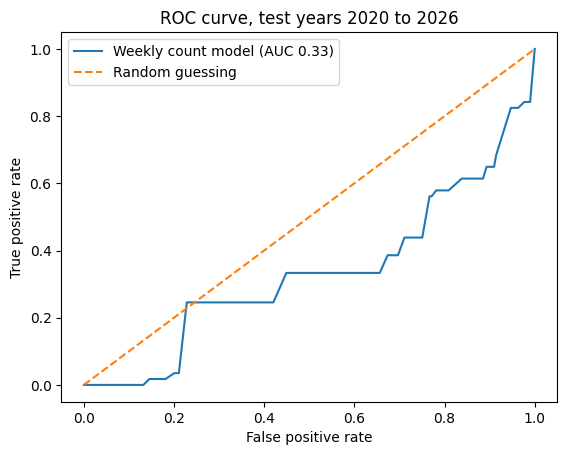

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(test_w["SEVERE"], probs_w)
auc = roc_auc_score(test_w["SEVERE"], probs_w)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"Weekly count model (AUC {auc:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve, test years 2020 to 2026")
ax.legend()

fig.savefig("roc_weekly_count.png", dpi=150, bbox_inches="tight")
plt.show()